In [2]:
import seaborn as sns
df = sns.load_dataset('penguins')
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [3]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [7]:
df[df['species'] == 'Adelie']

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
147,Adelie,Dream,36.6,18.4,184.0,3475.0,Female
148,Adelie,Dream,36.0,17.8,195.0,3450.0,Female
149,Adelie,Dream,37.8,18.1,193.0,3750.0,Male
150,Adelie,Dream,36.0,17.1,187.0,3700.0,Female


In [9]:
df.dtypes

,0
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object


In [10]:
df.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [11]:
df.duplicated().sum()

0

In [12]:
from scipy import stats
stats.zscore(df['bill_length_mm'])

,bill_length_mm
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
339,NaN
340,NaN
341,NaN
342,NaN


Identifying Outliers

In [21]:
import numpy as np
z_scores = np.abs(df['bill_length_mm'] - np.mean(df['bill_length_mm']))/np.std(df['bill_length_mm'])
outliers = df[z_scores > 3]
outliers


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex


There are no outliers

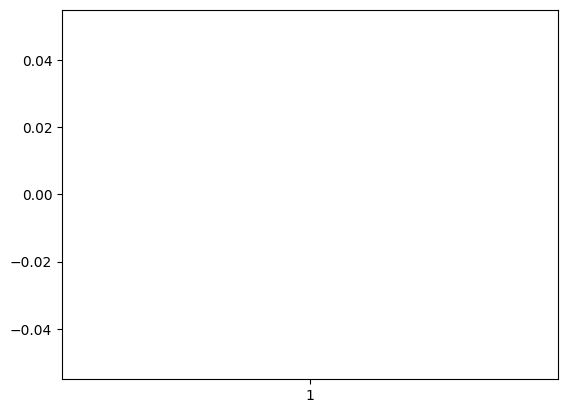

In [23]:
import matplotlib.pyplot as plt
plt.boxplot(x = df['bill_length_mm'])
plt.show()

In [24]:
np.median(df['bill_depth_mm'])

nan

In [32]:
data = df.fillna(np.median(df['bill_depth_mm']))

In [34]:
data['bill_depth_cm'] = data['bill_depth_mm']*0.1
data

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,bill_depth_cm
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,1.87
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,1.74
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,1.80
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,1.93
...,...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female,1.43
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male,1.57
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female,1.48


In [39]:
data = data.drop('bill_length_mm',axis = 1)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_depth_mm      342 non-null    float64
 3   flipper_length_mm  342 non-null    float64
 4   body_mass_g        342 non-null    float64
 5   sex                333 non-null    object 
 6   bill_depth_cm      342 non-null    float64
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [44]:
grouped_df = data.groupby('species')['bill_depth_cm'].mean()
grouped_df

,bill_depth_cm
species,
Adelie,1.834636
Chinstrap,1.842059
Gentoo,1.498211


In [47]:
grouped_df = data.groupby('species')['body_mass_g'].mean()
grouped_df.T

,body_mass_g
species,
Adelie,3700.662252
Chinstrap,3733.088235
Gentoo,5076.016260


In [48]:
grouped_df.info()

<class 'pandas.core.series.Series'>
Index: 3 entries, Adelie to Gentoo
Series name: body_mass_g
Non-Null Count  Dtype  
--------------  -----  
3 non-null      float64
dtypes: float64(1)
memory usage: 156.0+ bytes


In [51]:
grouped_df.rename('Mean_body_mass_g')
grouped_df

,body_mass_g
species,
Adelie,3700.662252
Chinstrap,3733.088235
Gentoo,5076.016260


In [52]:
# Filling Nan with mean
df['flipper_length_mm'] = df['flipper_length_mm'].fillna(df['flipper_length_mm'].mean())
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.000000,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.000000,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.000000,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,200.915205,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.000000,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,200.915205,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.000000,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.000000,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.000000,5200.0,Female


In [53]:
df['sex'].value_counts()

,count
sex,
Male,168
Female,165


In [55]:
df['sex'] = df['sex'].fillna(df['sex'].mode()[0])
df


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.000000,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.000000,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.000000,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,200.915205,NaN,Male
4,Adelie,Torgersen,36.7,19.3,193.000000,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,200.915205,NaN,Male
340,Gentoo,Biscoe,46.8,14.3,215.000000,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.000000,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.000000,5200.0,Female


In [56]:
df['island'].value_counts()

,count
island,
Biscoe,168
Dream,124
Torgersen,52


Crosstab in Python

In [58]:
import pandas as pd
cross_tab = pd.crosstab(df['species'],df['island'])
cross_tab

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


In [59]:
cross_tab = pd.crosstab(df['species'],df['flipper_length_mm'].mean())
cross_tab

col_0,200.915205
species,
Adelie,152
Chinstrap,68
Gentoo,124


In [60]:
cross_tab = pd.crosstab(df['species'],df['sex'])
cross_tab

sex,Female,Male
species,,
Adelie,73,79
Chinstrap,34,34
Gentoo,58,66


In [62]:
new_data = df.drop(['sex','species','island'],axis = 1)
new_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bill_length_mm     342 non-null    float64
 1   bill_depth_mm      342 non-null    float64
 2   flipper_length_mm  344 non-null    float64
 3   body_mass_g        342 non-null    float64
dtypes: float64(4)
memory usage: 10.9 KB


<Axes: >

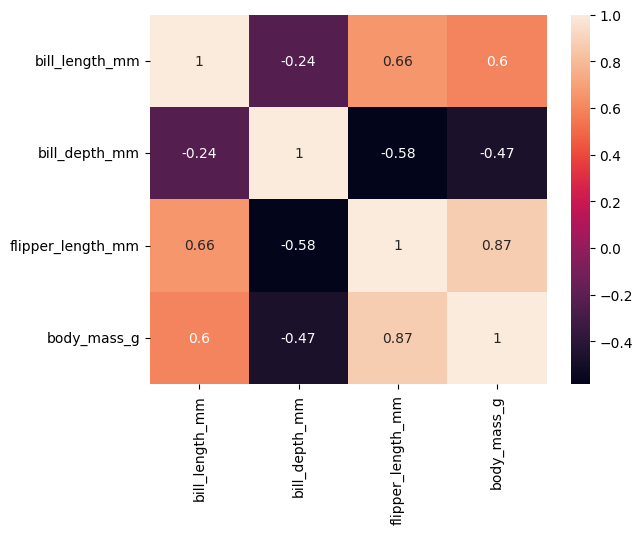

In [63]:
sns.heatmap(new_data.corr(),annot = True)

In [65]:
unique_sex = df['sex'].unique()
unique_sex

array(['Male', 'Female'], dtype=object)